In [ ]:
print("TEST OK")

PHASE 4 - MODEL EVALUATION

Project directory:
c:\Users\mvars\Downloads\open_lab

Processed data directory:
c:\Users\mvars\Downloads\open_lab\data\processed

Model directory:
c:\Users\mvars\Downloads\open_lab\models

Output directory:
c:\Users\mvars\Downloads\open_lab\outputs

Directories checked successfully.

PROCESSED DATA FILES
 - clean_wri_dataset.csv
 - features_exposure.txt
 - features_susceptibility.txt
 - features_vulnerability.txt
 - features_wri.txt
 - worldriskindex_cleaned.csv
 - X_test.csv
 - X_test_exposure.csv
 - X_test_susceptibility.csv
 - X_test_vulnerability.csv
 - X_test_wri.csv
 - X_train.csv
 - X_train_exposure.csv
 - X_train_susceptibility.csv
 - X_train_vulnerability.csv
 - X_train_wri.csv
 - y_test.csv
 - y_test_exposure.csv
 - y_test_susceptibility.csv
 - y_test_vulnerability.csv
 - y_test_wri.csv
 - y_train.csv
 - y_train_exposure.csv
 - y_train_susceptibility.csv
 - y_train_vulnerability.csv
 - y_train_wri.csv

LOADING TEST FEATURES

X_test loaded successfu

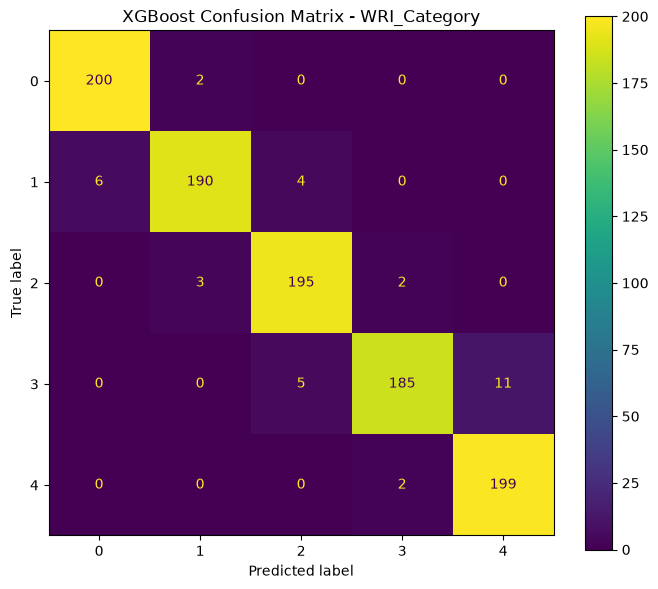

Saved: c:\Users\mvars\Downloads\open_lab\outputs\confusion_matrices\wri_category_xgboost_confusion_matrix.png


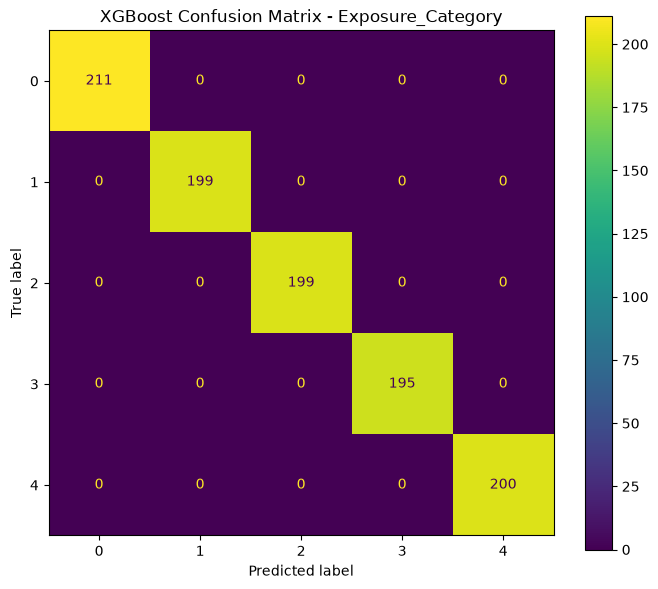

Saved: c:\Users\mvars\Downloads\open_lab\outputs\confusion_matrices\exposure_category_xgboost_confusion_matrix.png


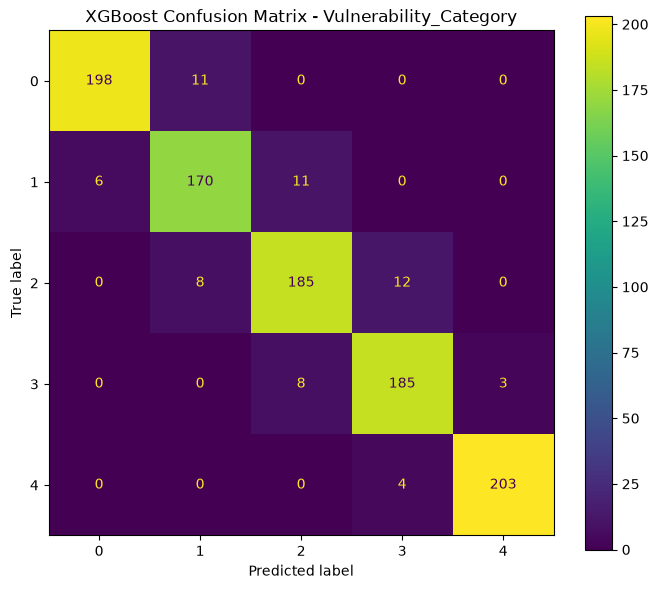

Saved: c:\Users\mvars\Downloads\open_lab\outputs\confusion_matrices\vulnerability_category_xgboost_confusion_matrix.png


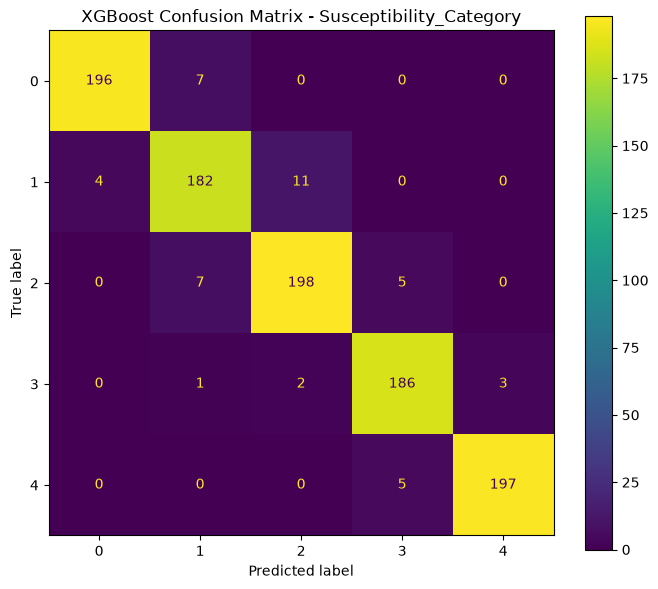

Saved: c:\Users\mvars\Downloads\open_lab\outputs\confusion_matrices\susceptibility_category_xgboost_confusion_matrix.png


PART B - SUSCEPTIBILITY MODEL COMPARISON


----------------------------------------------------------------------
Evaluating: XGBoost
----------------------------------------------------------------------
Accuracy : 0.9552
Precision: 0.9554
Recall   : 0.9552
F1       : 0.9552
AUC      : 0.9976


----------------------------------------------------------------------
Evaluating: Random Forest
----------------------------------------------------------------------
Accuracy : 0.9412
Precision: 0.9415
Recall   : 0.9412
F1       : 0.9413
AUC      : 0.9948


----------------------------------------------------------------------
Evaluating: SVM
----------------------------------------------------------------------
Accuracy : 0.8576
Precision: 0.8604
Recall   : 0.8576
F1       : 0.8585
AUC      : 0.9829


----------------------------------------------------------------------

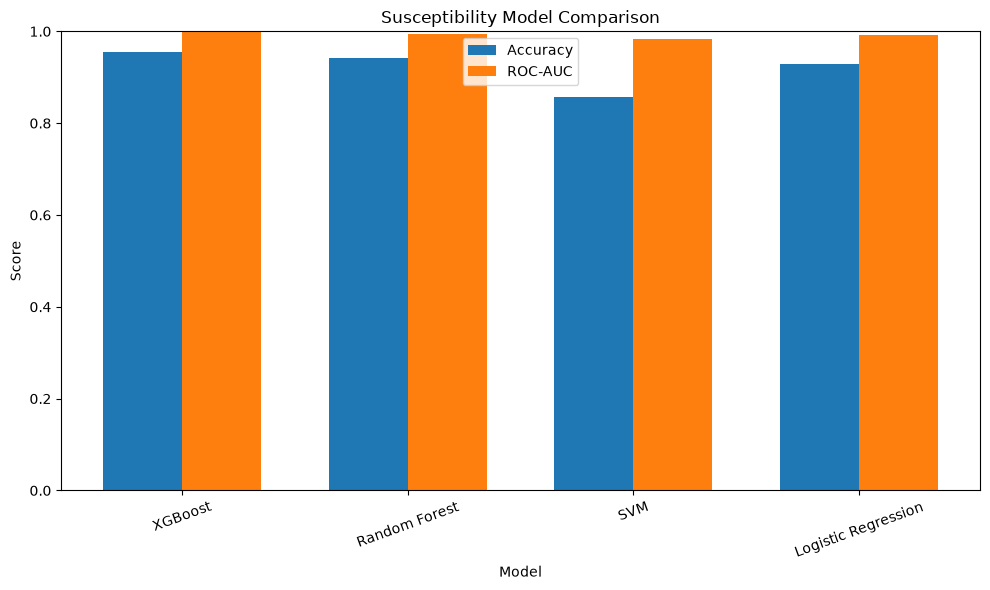

Saved: c:\Users\mvars\Downloads\open_lab\outputs\susceptibility_model_comparison.png


SUSCEPTIBILITY ROC CURVES


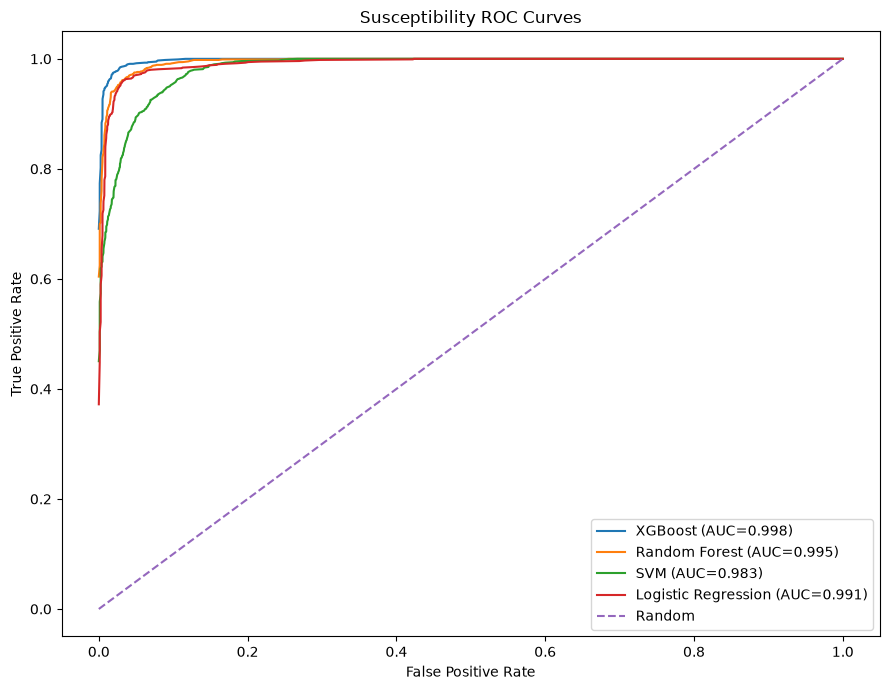

Saved: c:\Users\mvars\Downloads\open_lab\outputs\susceptibility_roc_curves.png


SUSCEPTIBILITY CONFUSION MATRICES


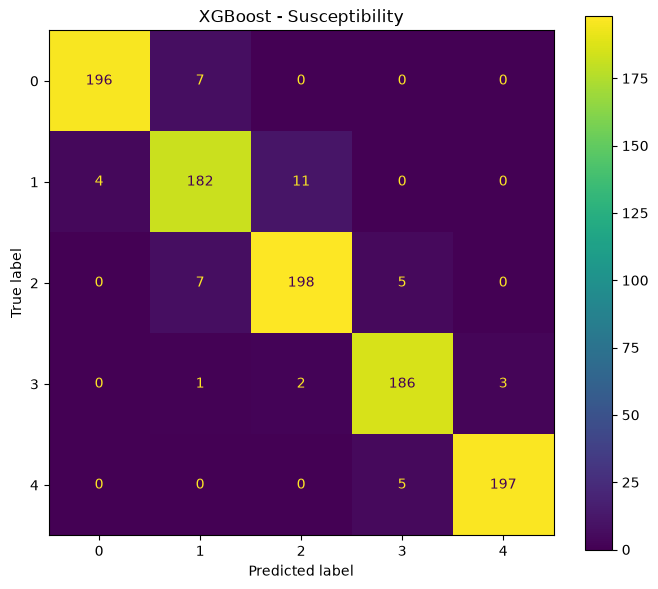

Saved: c:\Users\mvars\Downloads\open_lab\outputs\confusion_matrices\xgboost_susceptibility_confusion_matrix.png


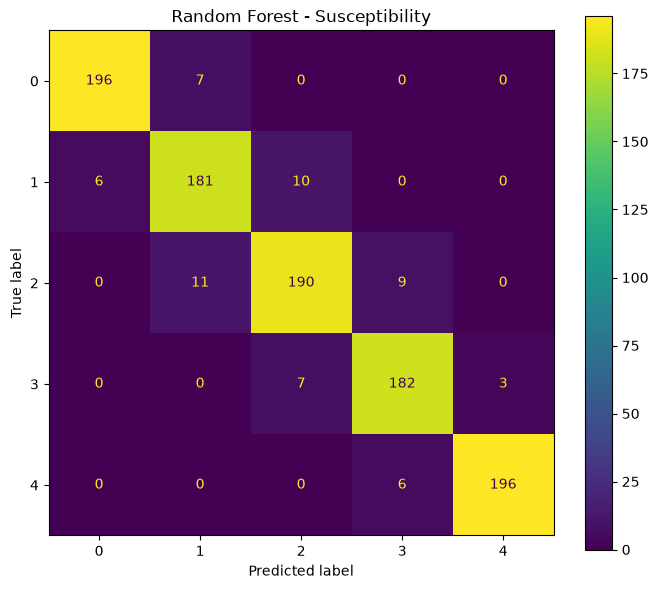

Saved: c:\Users\mvars\Downloads\open_lab\outputs\confusion_matrices\random_forest_susceptibility_confusion_matrix.png


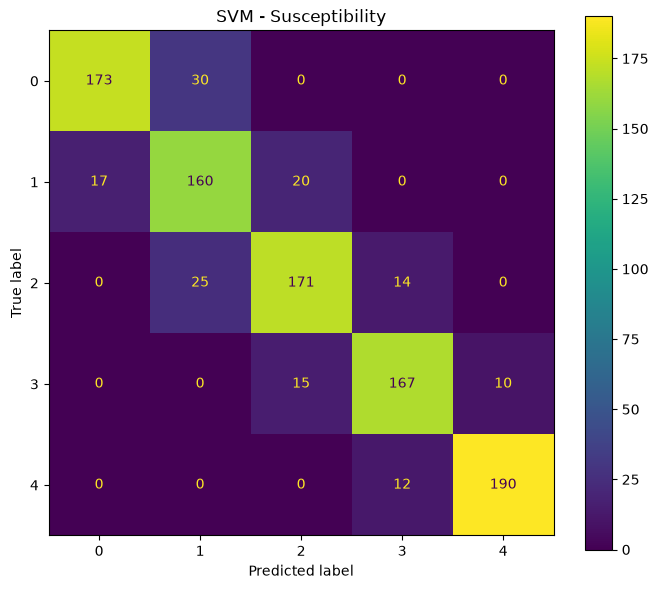

Saved: c:\Users\mvars\Downloads\open_lab\outputs\confusion_matrices\svm_susceptibility_confusion_matrix.png


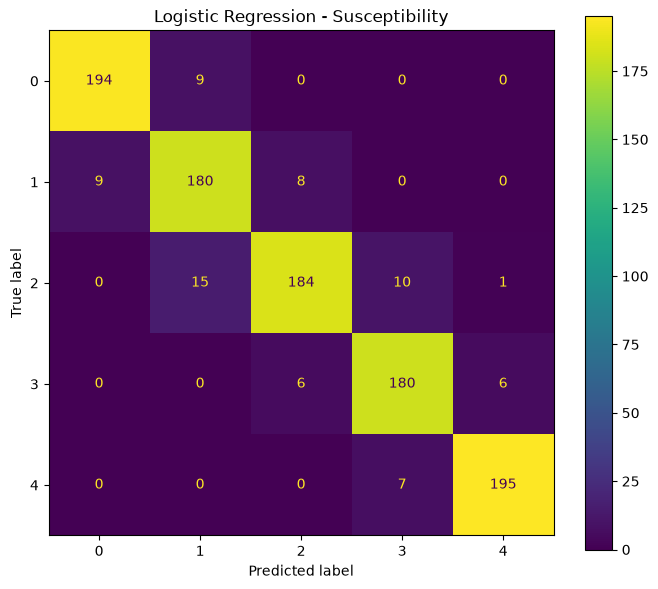

Saved: c:\Users\mvars\Downloads\open_lab\outputs\confusion_matrices\logistic_regression_susceptibility_confusion_matrix.png

Saved: c:\Users\mvars\Downloads\open_lab\outputs\phase4_complete_summary.txt


PHASE 4 COMPLETED SUCCESSFULLY

XGBoost evaluation:
                 Target  Accuracy  Precision   Recall       F1      AUC
           WRI_Category  0.965139   0.965520 0.965139 0.964988 0.997530
      Exposure_Category  1.000000   1.000000 1.000000 1.000000 1.000000
 Vulnerability_Category  0.937251   0.937594 0.937251 0.937357 0.994515
Susceptibility_Category  0.955179   0.955354 0.955179 0.955230 0.997593

Susceptibility model comparison:
              Model  Accuracy  Precision   Recall       F1      AUC
            XGBoost  0.955179   0.955354 0.955179 0.955230 0.997593
      Random Forest  0.941235   0.941474 0.941235 0.941299 0.994846
                SVM  0.857570   0.860355 0.857570 0.858454 0.982867
Logistic Regression  0.929283   0.929688 0.929283 0.929239 0.991082

Output di

In [10]:
# ============================================================
# PHASE 4 - MODEL EVALUATION
# ============================================================
#
# This phase evaluates the models trained in Phase 3.
#
# It DOES NOT retrain the models.
#
# According to the project/paper structure, we evaluate:
#
# PART A:
#   XGBoost for:
#       1. WRI
#       2. Exposure
#       3. Vulnerability
#       4. Susceptibility
#
# PART B:
#   Four-model comparison for Susceptibility:
#       1. XGBoost
#       2. Random Forest
#       3. SVM
#       4. Logistic Regression
#
# Metrics:
#   - Accuracy
#   - Precision
#   - Recall
#   - F1-score
#   - ROC-AUC
#
# Visualizations:
#   - Confusion matrices
#   - ROC curves
#   - Model comparison chart
#
# SHAP IS NOT DONE HERE.
# SHAP will be Phase 5.
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import warnings
import joblib

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve
)

from sklearn.preprocessing import label_binarize


warnings.filterwarnings("ignore")


# ============================================================
# 2. PROJECT PATHS
# ============================================================

# The notebook is inside:
#
# open_lab/
#     notebooks/
#         04_model_evaluation.ipynb
#
# Therefore ".." means the project root.

BASE_DIR = os.path.abspath("..")

PROCESSED_DIR = os.path.join(
    BASE_DIR,
    "data",
    "processed"
)

MODEL_DIR = os.path.join(
    BASE_DIR,
    "models"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "outputs"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


print("=" * 70)
print("PHASE 4 - MODEL EVALUATION")
print("=" * 70)

print("\nProject directory:")
print(BASE_DIR)

print("\nProcessed data directory:")
print(PROCESSED_DIR)

print("\nModel directory:")
print(MODEL_DIR)

print("\nOutput directory:")
print(OUTPUT_DIR)


# ============================================================
# 3. CHECK DIRECTORIES
# ============================================================

if not os.path.exists(PROCESSED_DIR):

    raise FileNotFoundError(
        "Processed data directory does not exist:\n"
        + PROCESSED_DIR
    )


if not os.path.exists(MODEL_DIR):

    raise FileNotFoundError(
        "Models directory does not exist:\n"
        + MODEL_DIR
    )


print("\nDirectories checked successfully.")


# ============================================================
# 4. SHOW AVAILABLE PROCESSED FILES
# ============================================================

print("\n" + "=" * 70)
print("PROCESSED DATA FILES")
print("=" * 70)

processed_files = os.listdir(PROCESSED_DIR)

for filename in processed_files:
    print(" -", filename)


# ============================================================
# 5. LOAD X_TEST
# ============================================================

print("\n" + "=" * 70)
print("LOADING TEST FEATURES")
print("=" * 70)


X_test_path = os.path.join(
    PROCESSED_DIR,
    "X_test.csv"
)


if not os.path.exists(X_test_path):

    raise FileNotFoundError(
        "X_test.csv was not found at:\n"
        + X_test_path
    )


X_test = pd.read_csv(
    X_test_path
)


# Remove accidental pandas index columns
# such as "Unnamed: 0".

unnamed_columns = [
    column
    for column in X_test.columns
    if str(column).startswith("Unnamed:")
]

if len(unnamed_columns) > 0:

    X_test = X_test.drop(
        columns=unnamed_columns
    )

    print(
        "\nRemoved accidental index columns:",
        unnamed_columns
    )


print("\nX_test loaded successfully.")

print(
    "X_test shape:",
    X_test.shape
)


# ============================================================
# 6. LOAD Y_TEST
# ============================================================
#
# First we look for:
#
#     y_test.csv
#
# If that does not exist, we load:
#
#     y_test_wri.csv
#     y_test_exposure.csv
#     y_test_vulnerability.csv
#     y_test_susceptibility.csv
#
# This makes the code compatible with both project layouts.
# ============================================================

print("\n" + "=" * 70)
print("LOADING TEST TARGETS")
print("=" * 70)


TARGETS = [
    "WRI_Category",
    "Exposure_Category",
    "Vulnerability_Category",
    "Susceptibility_Category"
]


y_test_path = os.path.join(
    PROCESSED_DIR,
    "y_test.csv"
)


if os.path.exists(y_test_path):

    print("\nFound combined y_test.csv")

    y_test = pd.read_csv(
        y_test_path
    )

    # Remove accidental index columns.
    unnamed_y_columns = [
        column
        for column in y_test.columns
        if str(column).startswith("Unnamed:")
    ]

    if len(unnamed_y_columns) > 0:

        y_test = y_test.drop(
            columns=unnamed_y_columns
        )


else:

    print(
        "\ny_test.csv not found."
    )

    print(
        "Loading the four individual target files..."
    )

    y_test = pd.DataFrame()

    target_file_map = {

        "WRI_Category":
            "y_test_wri.csv",

        "Exposure_Category":
            "y_test_exposure.csv",

        "Vulnerability_Category":
            "y_test_vulnerability.csv",

        "Susceptibility_Category":
            "y_test_susceptibility.csv"
    }


    for target_name, filename in target_file_map.items():

        file_path = os.path.join(
            PROCESSED_DIR,
            filename
        )

        if not os.path.exists(file_path):

            raise FileNotFoundError(
                "\nRequired test target file was not found:\n"
                + file_path
            )


        temp_df = pd.read_csv(
            file_path
        )


        # Remove accidental index columns.
        temp_unnamed = [
            column
            for column in temp_df.columns
            if str(column).startswith("Unnamed:")
        ]

        if len(temp_unnamed) > 0:

            temp_df = temp_df.drop(
                columns=temp_unnamed
            )


        # If the expected target name exists,
        # use that column.
        if target_name in temp_df.columns:

            y_test[target_name] = (
                temp_df[target_name]
            )

        # Otherwise use the first column.
        else:

            y_test[target_name] = (
                temp_df.iloc[:, 0]
            )


        print(
            "Loaded:",
            target_name,
            "->",
            len(y_test[target_name]),
            "rows"
        )


# ============================================================
# 7. CHECK TARGET COLUMNS
# ============================================================

print("\nTarget columns found:")

for column in y_test.columns:
    print(" -", column)


missing_targets = [
    target
    for target in TARGETS
    if target not in y_test.columns
]


if len(missing_targets) > 0:

    raise ValueError(
        "\nMissing target columns:\n"
        + str(missing_targets)
        + "\n\nAvailable columns:\n"
        + str(list(y_test.columns))
    )


print("\nAll four target columns found.")


# ============================================================
# 8. CHECK NUMBER OF TEST ROWS
# ============================================================

print("\nX_test rows:")
print(len(X_test))

print("\ny_test rows:")
print(len(y_test))


if len(X_test) != len(y_test):

    raise ValueError(
        "\nX_test and y_test contain different numbers of rows!\n"
        "X_test rows = "
        + str(len(X_test))
        + "\n"
        "y_test rows = "
        + str(len(y_test))
    )


print("\nRow-count check PASSED.")


# ============================================================
# 9. LOAD PHASE 3 MODELS
# ============================================================

print("\n" + "=" * 70)
print("LOADING PHASE 3 MODELS")
print("=" * 70)


all_models_file = os.path.join(
    MODEL_DIR,
    "phase3_all_models.pkl"
)


if not os.path.exists(all_models_file):

    raise FileNotFoundError(
        "\nCould not find Phase 3 model file:\n"
        + all_models_file
        + "\n\n"
        "Please make sure Phase 3 completed successfully "
        "and created phase3_all_models.pkl."
    )


print(
    "\nLoading:",
    all_models_file
)


all_models = joblib.load(
    all_models_file
)


print(
    "Phase 3 model file loaded successfully."
)


# ============================================================
# 10. DISPLAY CONTENTS OF MODEL FILE
# ============================================================

print("\nObjects stored in Phase 3 model file:")

if isinstance(all_models, dict):

    for key in all_models.keys():

        print(
            " -",
            key
        )

else:

    print(
        "WARNING: phase3_all_models.pkl is not a dictionary."
    )

    raise TypeError(
        "Expected phase3_all_models.pkl to contain a dictionary."
    )


# ============================================================
# 11. EXTRACT XGBOOST MODELS
# ============================================================

if "xgboost_four_targets" not in all_models:

    raise KeyError(
        "\nThe Phase 3 model file does not contain:\n"
        "'xgboost_four_targets'\n\n"
        "Available keys are:\n"
        + str(list(all_models.keys()))
    )


trained_xgb_models = all_models[
    "xgboost_four_targets"
]


print("\nXGBoost models loaded:")

for target in trained_xgb_models.keys():

    print(
        " -",
        target
    )


# ============================================================
# 12. EXTRACT COMPARISON MODELS
# ============================================================

if "susceptibility_comparison" not in all_models:

    raise KeyError(
        "\nThe Phase 3 model file does not contain:\n"
        "'susceptibility_comparison'\n\n"
        "The paper/project requires comparison of:\n"
        "XGBoost, Random Forest, SVM and Logistic Regression\n"
        "for Susceptibility."
    )


comparison_models = all_models[
    "susceptibility_comparison"
]


print("\nSusceptibility comparison models:")

for model_name in comparison_models.keys():

    print(
        " -",
        model_name
    )


# ============================================================
# 13. MAKE X_TEST MATCH THE TRAINING FEATURES
# ============================================================
#
# Sometimes CSV files contain an extra index column.
#
# XGBoost models trained using pandas normally contain
# feature_names_in_.
#
# If available, we use those exact features.
# ============================================================

def prepare_features_for_model(
    model,
    X
):

    X_copy = X.copy()


    # --------------------------------------------------------
    # If the model remembers feature names,
    # select the exact same features.
    # --------------------------------------------------------

    if hasattr(
        model,
        "feature_names_in_"
    ):

        required_features = list(
            model.feature_names_in_
        )


        missing_features = [
            feature
            for feature in required_features
            if feature not in X_copy.columns
        ]


        if len(missing_features) > 0:

            raise ValueError(
                "\nX_test is missing features required by the model:\n"
                + str(missing_features[:20])
            )


        X_copy = X_copy[
            required_features
        ]


    return X_copy


# Use the first XGBoost model to prepare X_test.

first_target = list(
    trained_xgb_models.keys()
)[0]


first_xgb_model = trained_xgb_models[
    first_target
]


X_test_model = prepare_features_for_model(
    first_xgb_model,
    X_test
)


print("\nFeatures used for model evaluation:")
print(
    X_test_model.shape
)


# ============================================================
# 14. TARGET VALUE CONVERSION
# ============================================================
#
# The paper uses five risk categories:
#
#   Very Low
#   Low
#   Medium
#   High
#   Very High
#
# The trained models may use numeric labels.
#
# We therefore convert string categories to:
#
#   0 = Very Low
#   1 = Low
#   2 = Medium
#   3 = High
#   4 = Very High
#
# If the dataset is already numeric, it remains numeric.
# ============================================================

CATEGORY_MAP = {

    "Very Low": 0,
    "very low": 0,

    "Low": 1,
    "low": 1,

    "Medium": 2,
    "medium": 2,

    "High": 3,
    "high": 3,

    "Very High": 4,
    "very high": 4
}


def convert_target_to_numeric(
    series
):

    # Already numeric
    if pd.api.types.is_numeric_dtype(series):

        return pd.to_numeric(
            series,
            errors="coerce"
        ).astype(int)


    # Convert strings
    converted = (
        series
        .astype(str)
        .str.strip()
        .map(CATEGORY_MAP)
    )


    # Check whether anything failed
    if converted.isna().any():

        bad_values = (
            series[
                converted.isna()
            ]
            .unique()
            .tolist()
        )


        raise ValueError(
            "\nUnknown target category values:\n"
            + str(bad_values)
            + "\n\nExpected categories:\n"
            + str(list(CATEGORY_MAP.keys()))
        )


    return converted.astype(int)


# Convert all targets.

for target in TARGETS:

    y_test[target] = (
        convert_target_to_numeric(
            y_test[target]
        )
    )


print("\nTarget conversion completed.")


# ============================================================
# 15. DISPLAY TARGET DISTRIBUTIONS
# ============================================================

print("\n" + "=" * 70)
print("TEST TARGET DISTRIBUTIONS")
print("=" * 70)


for target in TARGETS:

    print("\n" + target)

    print(
        y_test[target]
        .value_counts()
        .sort_index()
    )


# ============================================================
# 16. METRIC FUNCTION
# ============================================================

def calculate_metrics(
    y_true,
    predictions,
    probabilities,
    model_classes=None
):

    # --------------------------------------------------------
    # Accuracy
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_true,
        predictions
    )


    # --------------------------------------------------------
    # Precision
    # --------------------------------------------------------

    precision = precision_score(
        y_true,
        predictions,
        average="weighted",
        zero_division=0
    )


    # --------------------------------------------------------
    # Recall
    # --------------------------------------------------------

    recall = recall_score(
        y_true,
        predictions,
        average="weighted",
        zero_division=0
    )


    # --------------------------------------------------------
    # F1
    # --------------------------------------------------------

    f1 = f1_score(
        y_true,
        predictions,
        average="weighted",
        zero_division=0
    )


    # --------------------------------------------------------
    # ROC-AUC
    # --------------------------------------------------------

    auc_score = np.nan


    if probabilities is not None:

        try:

            # If the model provides its class ordering,
            # explicitly use it.
            if model_classes is not None:

                actual_classes = np.unique(
                    y_true
                )

                # Only calculate multiclass AUC when
                # the necessary classes are represented.
                if len(model_classes) > 2:

                    auc_score = roc_auc_score(
                        y_true,
                        probabilities,
                        multi_class="ovr",
                        average="weighted",
                        labels=model_classes
                    )

                else:

                    auc_score = roc_auc_score(
                        y_true,
                        probabilities[:, 1]
                    )

            else:

                if probabilities.shape[1] > 2:

                    auc_score = roc_auc_score(
                        y_true,
                        probabilities,
                        multi_class="ovr",
                        average="weighted"
                    )

                else:

                    auc_score = roc_auc_score(
                        y_true,
                        probabilities[:, 1]
                    )


        except Exception as error:

            print(
                "AUC could not be calculated:",
                str(error)
            )

            auc_score = np.nan


    return {

        "Accuracy": accuracy,

        "Precision": precision,

        "Recall": recall,

        "F1": f1,

        "AUC": auc_score
    }


# ============================================================
# 17. PART A - XGBOOST EVALUATION
# ============================================================

print("\n")
print("=" * 70)
print("PART A - XGBOOST EVALUATION")
print("=" * 70)


xgb_evaluation_results = []


for target in TARGETS:

    print("\n")
    print("-" * 70)
    print(
        "Evaluating XGBoost:",
        target
    )
    print("-" * 70)


    # --------------------------------------------------------
    # Check model exists
    # --------------------------------------------------------

    if target not in trained_xgb_models:

        raise KeyError(
            "\nXGBoost model missing for target:\n"
            + target
        )


    model = trained_xgb_models[
        target
    ]


    # --------------------------------------------------------
    # Prepare features
    # --------------------------------------------------------

    X_for_model = prepare_features_for_model(
        model,
        X_test
    )


    # --------------------------------------------------------
    # True values
    # --------------------------------------------------------

    y_true = y_test[
        target
    ]


    # --------------------------------------------------------
    # Predictions
    # --------------------------------------------------------

    predictions = model.predict(
        X_for_model
    )


    # --------------------------------------------------------
    # Probability predictions
    # --------------------------------------------------------

    probabilities = None

    if hasattr(
        model,
        "predict_proba"
    ):

        probabilities = model.predict_proba(
            X_for_model
        )


    # --------------------------------------------------------
    # Calculate metrics
    # --------------------------------------------------------

    model_classes = None

    if hasattr(
        model,
        "classes_"
    ):

        model_classes = model.classes_


    metrics = calculate_metrics(
        y_true,
        predictions,
        probabilities,
        model_classes
    )


    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    xgb_evaluation_results.append({

        "Target": target,

        "Accuracy":
            metrics["Accuracy"],

        "Precision":
            metrics["Precision"],

        "Recall":
            metrics["Recall"],

        "F1":
            metrics["F1"],

        "AUC":
            metrics["AUC"]
    })


    # --------------------------------------------------------
    # Print results
    # --------------------------------------------------------

    print(
        "Accuracy :",
        round(
            metrics["Accuracy"],
            4
        )
    )

    print(
        "Precision:",
        round(
            metrics["Precision"],
            4
        )
    )

    print(
        "Recall   :",
        round(
            metrics["Recall"],
            4
        )
    )

    print(
        "F1       :",
        round(
            metrics["F1"],
            4
        )
    )

    if pd.isna(
        metrics["AUC"]
    ):

        print(
            "AUC      : Not available"
        )

    else:

        print(
            "AUC      :",
            round(
                metrics["AUC"],
                4
            )
        )


# ============================================================
# 18. XGBOOST RESULTS TABLE
# ============================================================

xgb_results_df = pd.DataFrame(
    xgb_evaluation_results
)


print("\n")
print("=" * 70)
print("XGBOOST TEST-SET RESULTS")
print("=" * 70)


print(
    xgb_results_df.to_string(
        index=False
    )
)


# ============================================================
# 19. SAVE XGBOOST RESULTS
# ============================================================

xgb_results_file = os.path.join(
    OUTPUT_DIR,
    "phase4_xgboost_evaluation.csv"
)


xgb_results_df.to_csv(
    xgb_results_file,
    index=False
)


print(
    "\nSaved:",
    xgb_results_file
)


# ============================================================
# 20. CLASSIFICATION REPORTS
# ============================================================

print("\n")
print("=" * 70)
print("XGBOOST CLASSIFICATION REPORTS")
print("=" * 70)


classification_report_dir = os.path.join(
    OUTPUT_DIR,
    "classification_reports"
)


os.makedirs(
    classification_report_dir,
    exist_ok=True
)


for target in TARGETS:

    print("\n")
    print("-" * 70)
    print(target)
    print("-" * 70)


    model = trained_xgb_models[
        target
    ]


    X_for_model = prepare_features_for_model(
        model,
        X_test
    )


    y_true = y_test[
        target
    ]


    predictions = model.predict(
        X_for_model
    )


    report = classification_report(
        y_true,
        predictions,
        zero_division=0
    )


    print(report)


    report_filename = (
        target.lower()
        + "_classification_report.txt"
    )


    report_path = os.path.join(
        classification_report_dir,
        report_filename
    )


    with open(
        report_path,
        "w",
        encoding="utf-8"
    ) as file:

        file.write(report)


# ============================================================
# 21. XGBOOST CONFUSION MATRICES
# ============================================================

print("\n")
print("=" * 70)
print("XGBOOST CONFUSION MATRICES")
print("=" * 70)


confusion_dir = os.path.join(
    OUTPUT_DIR,
    "confusion_matrices"
)


os.makedirs(
    confusion_dir,
    exist_ok=True
)


for target in TARGETS:

    model = trained_xgb_models[
        target
    ]


    X_for_model = prepare_features_for_model(
        model,
        X_test
    )


    y_true = y_test[
        target
    ]


    predictions = model.predict(
        X_for_model
    )


    cm = confusion_matrix(
        y_true,
        predictions
    )


    fig, ax = plt.subplots(
        figsize=(7, 6)
    )


    ConfusionMatrixDisplay(
        confusion_matrix=cm
    ).plot(
        ax=ax
    )


    ax.set_title(
        "XGBoost Confusion Matrix - "
        + target
    )


    plt.tight_layout()


    filename = (
        target.lower()
        + "_xgboost_confusion_matrix.png"
    )


    filepath = os.path.join(
        confusion_dir,
        filename
    )


    plt.savefig(
        filepath,
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()


    plt.close()


    print(
        "Saved:",
        filepath
    )


# ============================================================
# 22. PART B - SUSCEPTIBILITY MODEL COMPARISON
# ============================================================
#
# This is the comparison required by the paper:
#
#   XGBoost
#   Random Forest
#   SVM
#   Logistic Regression
#
# evaluated on:
#
#   Susceptibility_Category
# ============================================================

print("\n")
print("=" * 70)
print("PART B - SUSCEPTIBILITY MODEL COMPARISON")
print("=" * 70)


susceptibility_target = (
    "Susceptibility_Category"
)


y_sus_test = y_test[
    susceptibility_target
]


susceptibility_results = []


for model_name, model in comparison_models.items():

    print("\n")
    print("-" * 70)
    print(
        "Evaluating:",
        model_name
    )
    print("-" * 70)


    # --------------------------------------------------------
    # Prepare features
    # --------------------------------------------------------

    X_for_model = prepare_features_for_model(
        model,
        X_test
    )


    # --------------------------------------------------------
    # Predictions
    # --------------------------------------------------------

    predictions = model.predict(
        X_for_model
    )


    # --------------------------------------------------------
    # Probabilities
    # --------------------------------------------------------

    probabilities = None

    if hasattr(
        model,
        "predict_proba"
    ):

        probabilities = model.predict_proba(
            X_for_model
        )


    # --------------------------------------------------------
    # Classes
    # --------------------------------------------------------

    model_classes = None

    if hasattr(
        model,
        "classes_"
    ):

        model_classes = model.classes_


    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    metrics = calculate_metrics(
        y_sus_test,
        predictions,
        probabilities,
        model_classes
    )


    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    susceptibility_results.append({

        "Model":
            model_name,

        "Accuracy":
            metrics["Accuracy"],

        "Precision":
            metrics["Precision"],

        "Recall":
            metrics["Recall"],

        "F1":
            metrics["F1"],

        "AUC":
            metrics["AUC"]
    })


    # --------------------------------------------------------
    # Print results
    # --------------------------------------------------------

    print(
        "Accuracy :",
        round(
            metrics["Accuracy"],
            4
        )
    )

    print(
        "Precision:",
        round(
            metrics["Precision"],
            4
        )
    )

    print(
        "Recall   :",
        round(
            metrics["Recall"],
            4
        )
    )

    print(
        "F1       :",
        round(
            metrics["F1"],
            4
        )
    )


    if pd.isna(
        metrics["AUC"]
    ):

        print(
            "AUC      : Not available"
        )

    else:

        print(
            "AUC      :",
            round(
                metrics["AUC"],
                4
            )
        )


# ============================================================
# 23. SUSCEPTIBILITY COMPARISON TABLE
# ============================================================

susceptibility_results_df = pd.DataFrame(
    susceptibility_results
)


print("\n")
print("=" * 70)
print("SUSCEPTIBILITY MODEL COMPARISON")
print("=" * 70)


print(
    susceptibility_results_df.to_string(
        index=False
    )
)


# ============================================================
# 24. SAVE COMPARISON TABLE
# ============================================================

comparison_file = os.path.join(
    OUTPUT_DIR,
    "phase4_susceptibility_model_comparison.csv"
)


susceptibility_results_df.to_csv(
    comparison_file,
    index=False
)


print(
    "\nSaved:",
    comparison_file
)


# ============================================================
# 25. MODEL COMPARISON CHART
# ============================================================

print("\n")
print("=" * 70)
print("SUSCEPTIBILITY MODEL COMPARISON CHART")
print("=" * 70)


models = susceptibility_results_df[
    "Model"
].tolist()


accuracy_values = susceptibility_results_df[
    "Accuracy"
].values


auc_values = susceptibility_results_df[
    "AUC"
].values


x = np.arange(
    len(models)
)


width = 0.35


fig, ax = plt.subplots(
    figsize=(10, 6)
)


ax.bar(
    x - width / 2,
    accuracy_values,
    width,
    label="Accuracy"
)


ax.bar(
    x + width / 2,
    auc_values,
    width,
    label="ROC-AUC"
)


ax.set_xlabel(
    "Model"
)


ax.set_ylabel(
    "Score"
)


ax.set_title(
    "Susceptibility Model Comparison"
)


ax.set_xticks(
    x
)


ax.set_xticklabels(
    models,
    rotation=20
)


ax.set_ylim(
    0,
    1
)


ax.legend()


plt.tight_layout()


comparison_plot_file = os.path.join(
    OUTPUT_DIR,
    "susceptibility_model_comparison.png"
)


plt.savefig(
    comparison_plot_file,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


plt.close()


print(
    "Saved:",
    comparison_plot_file
)


# ============================================================
# 26. ROC CURVES - SUSCEPTIBILITY
# ============================================================

print("\n")
print("=" * 70)
print("SUSCEPTIBILITY ROC CURVES")
print("=" * 70)


fig, ax = plt.subplots(
    figsize=(9, 7)
)


# ------------------------------------------------------------
# Loop through all four comparison models
# ------------------------------------------------------------

for model_name, model in comparison_models.items():

    X_for_model = prepare_features_for_model(
        model,
        X_test
    )


    if not hasattr(
        model,
        "predict_proba"
    ):

        print(
            "Skipping ROC curve for",
            model_name,
            "- no predict_proba method."
        )

        continue


    probabilities = model.predict_proba(
        X_for_model
    )


    model_classes = model.classes_


    # --------------------------------------------------------
    # Binarize true labels using the model's class order
    # --------------------------------------------------------

    y_binary = label_binarize(
        y_sus_test,
        classes=model_classes
    )


    # --------------------------------------------------------
    # Handle binary classification separately
    # --------------------------------------------------------

    if len(model_classes) == 2:

        fpr, tpr, _ = roc_curve(
            y_sus_test,
            probabilities[:, 1],
            pos_label=model_classes[1]
        )


        try:

            auc_score = roc_auc_score(
                y_sus_test,
                probabilities[:, 1]
            )

        except Exception:

            auc_score = np.nan


        ax.plot(
            fpr,
            tpr,
            label=(
                model_name
                + " (AUC="
                + f"{auc_score:.3f}"
                + ")"
            )
        )


    # --------------------------------------------------------
    # Multiclass ROC
    # --------------------------------------------------------

    else:

        all_fpr = np.unique(
            np.concatenate(
                [
                    roc_curve(
                        y_binary[:, i],
                        probabilities[:, i]
                    )[0]

                    for i in range(
                        len(model_classes)
                    )
                ]
            )
        )


        mean_tpr = np.zeros_like(
            all_fpr,
            dtype=float
        )


        for i in range(
            len(model_classes)
        ):

            fpr_i, tpr_i, _ = roc_curve(
                y_binary[:, i],
                probabilities[:, i]
            )


            mean_tpr += np.interp(
                all_fpr,
                fpr_i,
                tpr_i
            )


        mean_tpr /= len(
            model_classes
        )


        try:

            auc_score = roc_auc_score(
                y_sus_test,
                probabilities,
                multi_class="ovr",
                average="weighted",
                labels=model_classes
            )

        except Exception:

            auc_score = np.nan


        ax.plot(
            all_fpr,
            mean_tpr,
            label=(
                model_name
                + " (AUC="
                + f"{auc_score:.3f}"
                + ")"
            )
        )


# ------------------------------------------------------------
# Random classifier reference
# ------------------------------------------------------------

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random"
)


ax.set_xlabel(
    "False Positive Rate"
)


ax.set_ylabel(
    "True Positive Rate"
)


ax.set_title(
    "Susceptibility ROC Curves"
)


ax.legend(
    loc="lower right"
)


plt.tight_layout()


roc_file = os.path.join(
    OUTPUT_DIR,
    "susceptibility_roc_curves.png"
)


plt.savefig(
    roc_file,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


plt.close()


print(
    "Saved:",
    roc_file
)


# ============================================================
# 27. SUSCEPTIBILITY CONFUSION MATRICES
# ============================================================

print("\n")
print("=" * 70)
print("SUSCEPTIBILITY CONFUSION MATRICES")
print("=" * 70)


for model_name, model in comparison_models.items():

    X_for_model = prepare_features_for_model(
        model,
        X_test
    )


    predictions = model.predict(
        X_for_model
    )


    cm = confusion_matrix(
        y_sus_test,
        predictions
    )


    fig, ax = plt.subplots(
        figsize=(7, 6)
    )


    ConfusionMatrixDisplay(
        confusion_matrix=cm
    ).plot(
        ax=ax
    )


    ax.set_title(
        model_name
        + " - Susceptibility"
    )


    plt.tight_layout()


    safe_model_name = (
        model_name
        .lower()
        .replace(
            " ",
            "_"
        )
    )


    filename = (
        safe_model_name
        + "_susceptibility_confusion_matrix.png"
    )


    filepath = os.path.join(
        confusion_dir,
        filename
    )


    plt.savefig(
        filepath,
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()


    plt.close()


    print(
        "Saved:",
        filepath
    )


# ============================================================
# 28. SAVE COMPLETE PHASE 4 SUMMARY
# ============================================================

summary_file = os.path.join(
    OUTPUT_DIR,
    "phase4_complete_summary.txt"
)


with open(
    summary_file,
    "w",
    encoding="utf-8"
) as file:

    file.write(
        "PHASE 4 - MODEL EVALUATION\n"
    )

    file.write(
        "=" * 70
        + "\n\n"
    )


    file.write(
        "XGBOOST RESULTS\n"
    )

    file.write(
        "-" * 70
        + "\n"
    )


    file.write(
        xgb_results_df.to_string(
            index=False
        )
    )


    file.write(
        "\n\n"
    )


    file.write(
        "SUSCEPTIBILITY MODEL COMPARISON\n"
    )

    file.write(
        "-" * 70
        + "\n"
    )


    file.write(
        susceptibility_results_df.to_string(
            index=False
        )
    )


print(
    "\nSaved:",
    summary_file
)


# ============================================================
# 29. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 70)
print("PHASE 4 COMPLETED SUCCESSFULLY")
print("=" * 70)


print("\nXGBoost evaluation:")
print(
    xgb_results_df.to_string(
        index=False
    )
)


print("\nSusceptibility model comparison:")
print(
    susceptibility_results_df.to_string(
        index=False
    )
)


print("\nOutput directory:")
print(
    OUTPUT_DIR
)


print("\nGenerated important files:")

print(
    "1. phase4_xgboost_evaluation.csv"
)

print(
    "2. phase4_susceptibility_model_comparison.csv"
)

print(
    "3. susceptibility_model_comparison.png"
)

print(
    "4. susceptibility_roc_curves.png"
)

print(
    "5. confusion matrices"
)

print(
    "6. classification reports"
)


print("\n" + "=" * 70)
print("READY FOR PHASE 5 - SHAP ANALYSIS")
print("=" * 70)